# Unit 1 / Chapter 1: Foundations of Quantum Computing

> **Main Learning Objective:** Build the mental model you need for the rest of the course. By the end of Unit 1 you will know what a qubit is, what superposition and measurement actually do, what quantum gates do to a state, and what entanglement means.

| Section | Topic | What you will learn |
|---|---|---|
| 1.1 | Why Quantum Computing for AI | The limits of classical AI and where quantum methods can help |
| 1.2 | Qubits and Quantum States | Superposition, probability amplitudes, measurement collapse |
| 1.3 | Quantum Gates and Circuits | Single and multi-qubit gates, building real quantum circuits |

By the end of this unit you should be able to:

1. Explain in plain language why a qubit is more powerful than a bit.
2. Write down a qubit state and compute the measurement probabilities.
3. Describe what the Hadamard, Pauli-X, and CNOT gates do.
4. Recognize when two qubits are entangled vs independent.
5. Sketch a tiny quantum circuit on paper.

---

# Section 1.1: Why Quantum Computing for AI

## What today's AI is good and bad at

Artificial intelligence is everywhere in the workforce today. It helps people across many domains in their everyday work, but it still has real limitations.

The most talked about limitations right now are:

- **Hallucinations.** AI models can and will generate incorrect or partially correct information while confidently stating it is the correct answer. Every answer needs an expert check.
- **Lack of deep reasoning.** AI is good at simple queries but struggles with complex ones that need genuine multi step reasoning.
- **Very limited creativity.** AI rearranges patterns it has seen before. It cannot easily create truly new ideas.
- **High data dependency.** If the training data is poor, the outputs suffer. Big models need enormous amounts of high quality data.

## Where quantum can help

Quantum computing does not fix hallucinations, but it can help with three specific bottlenecks in AI:

1. **Speed.** Quantum matrix operations may let AI models process large amounts of data in parallel instead of step by step.
2. **Pattern discovery.** Superposition and entanglement let quantum systems explore very complex, hidden patterns in large data sets.
3. **Hard optimization.** Many AI problems (logistics, portfolio management, drug discovery) are combinatorial. Quantum methods have a natural angle on those.

## Classical vs quantum computers

The core difference is what the computer uses to store a piece of information.

| | Classical computer | Quantum computer |
|---|---|---|
| Basic unit | Bit (0 or 1) | Qubit (0, 1, or both at once) |
| Processing | Step by step | Many possibilities at once (superposition) |
| Best at | Everyday tasks: browse, spreadsheet, video | Specific hard problems: molecular simulation, huge search, sampling |
| Hardware | Silicon transistors | Superconducting, trapped ion, or photonic qubits |
| Everyday example | Google, YouTube, banking | Not in your pocket yet; running in labs and cloud today |

## What you will actually build in this course

Section 1.1 is intentionally big picture. To make the AI plus quantum connection concrete, here is a preview of things you will code with your own hands:

| Unit | Concrete AI plus quantum thing you will do |
|---|---|
| 2 | Watch Grover's algorithm find a target in a search space of 64 items using only 6 qubits |
| 3 | Train a quantum classifier and watch its decision boundary move as it learns |
| 4 | Run VQE to find a small molecule's ground state, then use QAOA on Max-Cut |
| 5 | Design your own quantum AI industry proposal for finance, drug discovery, or materials |
| 6 to 10 | Quantum linear algebra, error correction, RL, generative models, AI for quantum |

If any of the words above are unfamiliar, that is fine. Unit 1 is where we build the vocabulary.

---
# Section 1.2: Qubits and Quantum States

As mentioned in 1.1, there is a difference in the types of bits used between quantum and classical computers. A classical bit is binary and deterministic. At any moment, a classical bit can only be 0 or 1 since it has a definite state. A qubit is much different. A qubit can be 0, 1, or a combination of both at the same time, this is called **superposition**.

Imagine a coin lying flat. One can clearly see that the coin is either heads or tails, which is like a classical bit. What if we had a coin that is spinning on its side? The coin is neither clearly heads nor tails, and it represents a qubit which uses the superposition principle.

---
## The Qubit State Formula

A qubit state is written mathematically as:

$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$$

Where:
- $|0\rangle$ = basis state 0
- $|1\rangle$ = basis state 1
- $\alpha, \beta$ = complex probability amplitudes

The **Probability Constraint** requires:

$$|\alpha|^2 + |\beta|^2 = 1$$

- $|\alpha|^2$ = probability of measuring 0
- $|\beta|^2$ = probability of measuring 1

**Example:** If $\alpha = \frac{1}{\sqrt{2}}$ and $\beta = \frac{1}{\sqrt{2}}$, there is a 50% chance of measuring 0 and a 50% chance of measuring 1.

---
## Superposition and Quantum Parallelism

As stated prior, the qubit can exist in multiple states at the same time until measured, this is the principle of **superposition**. This is the foundation of quantum parallelism, which allows computers to solve problems simultaneously, exponentially increasing computational power. A quantum system with $n$ qubits can exist in $2^n$ states simultaneously.

> *(Enter a short, less than 1-minute video here explaining quantum parallelism with an example.)*

Some algorithms that use quantum parallelism are **Shor's algorithm** for factorization and **Grover's algorithm** for search, which we will cover in more depth later.

> **Common Misconception:** A quantum computer does *not* try every answer at once and pick the right one. Instead, it encodes possible answers as amplitudes, manipulates those amplitudes with algorithms, and then yields a result based on probability.

---
## Measurement and Wavefunction Collapse

**Measurement** is the process of interacting with a quantum state to obtain information. This causes the system to collapse from superposition into a single, definite state, called **wavefunction collapse**. Measurement is not reversible; once the state has collapsed, the original superposition cannot be recovered.

**Example:**

Recall the qubit state formula:
$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$$

Plugging in values:
$$|\psi\rangle = \frac{1}{\sqrt{3}}|0\rangle + \sqrt{\frac{2}{3}}|1\rangle$$

Squaring the magnitudes using the **Born Rule**:
$$P(0) = \frac{1}{3} \qquad P(1) = \frac{2}{3}$$

If you measure the qubit a second time, you will get the **exact same result** every time, because measurement collapsed the state.

---
## 🧪 Interactive Activities: Qubit Exploration

Now that we have some basic concepts down, let's try interacting with them!

**How to run the cells below:**
1. Click on a code cell to select it.
2. Press **Shift + Enter** to run it.
3. Run the cells **in order from top to bottom**, do not skip any!
4. If you change a slider or value, re-run the cell to see the updated result.

**What to look for:**
- **Randomness:** Each measurement may give a different result.
- **Patterns:** Even though results are random, they follow predictable probabilities.
- **Collapse:** After measuring, the qubit becomes a definite state (0 or 1).

### Step 1 of 6, Import Tools

This cell loads the Python libraries we need. Think of it like gathering your supplies before starting an experiment.

- **numpy** handles the math (probabilities, square roots, etc.)
- **matplotlib** draws the charts
- **ipywidgets** creates the interactive sliders

▶ **Run this cell first before anything else.**

In [13]:
# ── Step 1: Import libraries ──────────────────────────────────────────────────
# These lines load the tools we need. You don't need to change anything here.

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

try:
    import ipywidgets as widgets
    from IPython.display import display
    widgets_available = True
    print("✅ All libraries loaded successfully!")
except ImportError:
    widgets_available = False
    print("⚠️  ipywidgets not found. Sliders will not work.")
    print("   To fix: run   pip install ipywidgets   in a terminal.")

✅ All libraries loaded successfully!


---
## Course check-in

This logs that you started **Unit 1**. You will be asked to enter the email you signed up with so we can track your progress and email your certificate when you finish all units.

In [14]:
# # ============================================================
# # COURSE TRACKING - do not edit
# # ============================================================
# import json
# from urllib.request import Request, urlopen
# from urllib.error  import URLError

# UNIT_NUMBER = 1
# TRACKER_URL = "https://script.google.com/macros/s/AKfycbyp01BDLgzqHk5HbYt7Tl0hYESKo4qRs8AMJsFKUfbNKdbUuzjT6yb1L2qVFd_oz2Ur/exec"

# def _post_event(event_type, payload=None):
#     body = json.dumps({
#         "event_type": event_type,
#         "email":      _student_email,
#         "unit":       UNIT_NUMBER,
#         "payload":    payload or {}
#     }).encode("utf-8")
#     try:
#         req = Request(TRACKER_URL, data=body,
#                       headers={"Content-Type": "text/plain;charset=utf-8"})
#         urlopen(req, timeout=10).read()
#     except URLError as e:
#         print("(could not reach tracker:", e, ")")

# _student_email = input("Enter the email you signed up with: ").strip().lower()
# if "@" not in _student_email:
#     raise ValueError("That does not look like a valid email. Re-run this cell.")

# print(f"Hi {_student_email}! Logging that you started Unit {UNIT_NUMBER}.")
# _post_event("unit_started")

### Step 2 of 6, Define Qubit Helper Functions

Here we define three reusable functions:

| Function | What it does |
|---|---|
| `normalize(α, β)` | Scales α and β so that $ |α|^2 + |β|^2 = 1 $ |
| `create_qubit(α, β)` | Builds a qubit state vector from α and β |
| `measure(qubit)` | Simulates one measurement, returns 0 or 1 randomly based on probability |
| `run_experiment(qubit, trials)` | Repeats measurement many times and collects results |

▶ **Run this cell to define the functions.**

In [15]:
# ── Step 2: Define qubit helper functions ─────────────────────────────────────

def normalize(alpha, beta):
    """Rescale alpha and beta so that |alpha|^2 + |beta|^2 = 1."""
    norm = np.sqrt(abs(alpha)**2 + abs(beta)**2)
    return alpha / norm, beta / norm


def create_qubit(alpha, beta):
    """Build a qubit state vector [alpha, beta] and normalize it."""
    a, b = normalize(alpha, beta)
    return np.array([a, b])


def measure(qubit):
    """
    Simulate one measurement of the qubit.
    Returns 0 or 1 based on the qubit's probabilities.
    """
    p0 = abs(qubit[0])**2   # probability of measuring |0>
    p1 = abs(qubit[1])**2   # probability of measuring |1>
    return np.random.choice([0, 1], p=[p0, p1])


def run_experiment(qubit, trials=1000):
    """Measure the qubit `trials` times and return all outcomes as a list."""
    return [measure(qubit) for _ in range(trials)]


print("✅ Functions defined!")

✅ Functions defined!


### Step 3 of 6, Activity 1 & 2: Build a Qubit and Take Single Measurements

We will use the values from the example in the notes:
$$\alpha = \frac{1}{\sqrt{3}}, \quad \beta = \sqrt{\frac{2}{3}}$$

This means $P(0) = \frac{1}{3}$ and $P(1) = \frac{2}{3}$.

We will then measure the qubit 5 times. Notice that the result can be different each time!

> 💡 **Remember:** The qubit is in superposition until measured. Each measurement collapses it randomly based on probabilities.

▶ **Run this cell and observe the output.**

In [16]:
# ── Activity 1: Build a Qubit ─────────────────────────────────────────────────

alpha = 1 / np.sqrt(3)
beta  = np.sqrt(2 / 3)

psi = create_qubit(alpha, beta)

print("Qubit state vector:", np.round(psi, 4))
print(f"  P(0) = |α|² = {abs(psi[0])**2:.4f}  →  about {abs(psi[0])**2*100:.1f}% chance of measuring 0")
print(f"  P(1) = |β|² = {abs(psi[1])**2:.4f}  →  about {abs(psi[1])**2*100:.1f}% chance of measuring 1")

print()

# ── Activity 2: Single Measurements ──────────────────────────────────────────
print("Activity 2, Single Measurements")
print("Taking 5 individual measurements. Each run may give a different result:")
print()

for i in range(5):
    result = measure(psi)
    print(f"  Measurement {i+1}: {result}")

print()
print("❓ Question: Why are the results different each time?")
print("   (Think about superposition and the probability constraint.)")

Qubit state vector: [0.5774 0.8165]
  P(0) = |α|² = 0.3333  →  about 33.3% chance of measuring 0
  P(1) = |β|² = 0.6667  →  about 66.7% chance of measuring 1

Activity 2, Single Measurements
Taking 5 individual measurements. Each run may give a different result:

  Measurement 1: 1
  Measurement 2: 1
  Measurement 3: 0
  Measurement 4: 0
  Measurement 5: 1

❓ Question: Why are the results different each time?
   (Think about superposition and the probability constraint.)


### Step 4 of 6, Activity 3 & 4: Many Measurements and Convergence

A single measurement is random. But if we measure **many times**, a pattern emerges, the outcomes converge to the true probabilities. This is called the **Law of Large Numbers**.

**Activity 3** runs 200 measurements and plots how many 0s and 1s we got.

**Activity 4** shows how the fraction of 1s stabilizes as we increase the number of trials.

▶ **Run this cell and study the two charts.**

Activity 3, Out of 200 measurements:
  Got 0: 61 times  (30.5%)
  Got 1: 139 times  (69.5%)
  True P(0) = 33.3%,  True P(1) = 66.7%


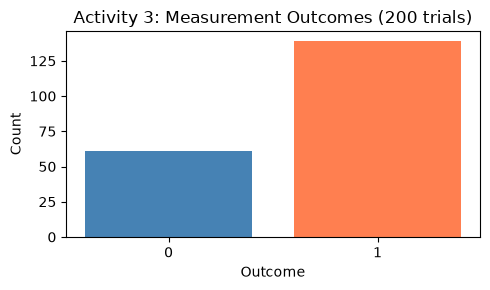

❓ Question: Do the results look random or patterned? What did you expect?

Activity 4, Convergence to True Probability
As the number of trials increases, the fraction of 1s stabilizes.


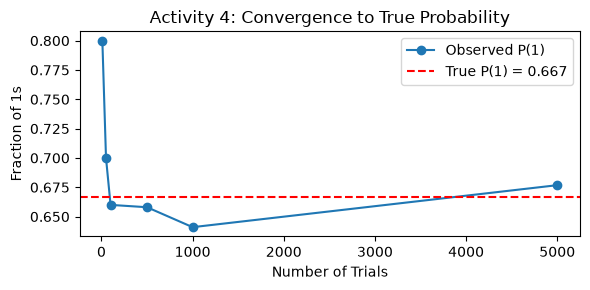

❓ Question: What happens as we increase the number of trials?
   (Notice how the orange dots get closer to the red dashed line.)


In [17]:
# ── Activity 3: Many Measurements ────────────────────────────────────────────

trials = 200
results = run_experiment(psi, trials)

count_0 = results.count(0)
count_1 = results.count(1)

print(f"Activity 3, Out of {trials} measurements:")
print(f"  Got 0: {count_0} times  ({count_0/trials*100:.1f}%)")
print(f"  Got 1: {count_1} times  ({count_1/trials*100:.1f}%)")
print(f"  True P(0) = {abs(psi[0])**2*100:.1f}%,  True P(1) = {abs(psi[1])**2*100:.1f}%")

plt.figure(figsize=(5, 3))
plt.bar(["0", "1"], [count_0, count_1], color=["steelblue", "coral"])
plt.title("Activity 3: Measurement Outcomes (200 trials)")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print("❓ Question: Do the results look random or patterned? What did you expect?")
print()

# ── Activity 4: Convergence ───────────────────────────────────────────────────

print("Activity 4, Convergence to True Probability")
print("As the number of trials increases, the fraction of 1s stabilizes.")

sizes = [10, 50, 100, 500, 1000, 5000]
proportions = []

for t in sizes:
    r = run_experiment(psi, t)
    proportions.append(r.count(1) / t)

true_p1 = abs(psi[1])**2

plt.figure(figsize=(6, 3))
plt.plot(sizes, proportions, marker='o', label="Observed P(1)")
plt.axhline(y=true_p1, color='red', linestyle='--', label=f"True P(1) = {true_p1:.3f}")
plt.title("Activity 4: Convergence to True Probability")
plt.xlabel("Number of Trials")
plt.ylabel("Fraction of 1s")
plt.legend()
plt.tight_layout()
plt.show()

print("❓ Question: What happens as we increase the number of trials?")
print("   (Notice how the orange dots get closer to the red dashed line.)")

### Step 5 of 6, Activity 5: Measurement Collapse

When you measure a qubit, it **collapses** into a definite state, either $|0\rangle$ or $|1\rangle$. After collapse, all future measurements give the **same result**.

This is fundamentally different from classical randomness. The qubit is not hiding a secret answer, the answer only becomes definite at the moment of measurement.

▶ **Run this cell and compare the first vs. second measurement.**

In [18]:
# ── Activity 5: Measurement Collapse ──────────────────────────────────────────

def measure_with_collapse(qubit):
    """
    Simulate measurement AND collapse.
    Returns:
      outcome   - the measured value (0 or 1)
      new_state - the qubit state after collapse
    """
    outcome = measure(qubit)
    if outcome == 0:
        collapsed_state = np.array([1, 0])  # |0> state
    else:
        collapsed_state = np.array([0, 1])  # |1> state
    return outcome, collapsed_state


print("Before measurement, qubit is in superposition:")
print(f"  State: α={np.round(psi[0],4)}, β={np.round(psi[1],4)}")
print(f"  P(0) = {abs(psi[0])**2:.3f},  P(1) = {abs(psi[1])**2:.3f}")
print()

outcome, collapsed = measure_with_collapse(psi)

print(f"First measurement result: {outcome}")
print(f"State after collapse: {collapsed}  ← now a definite state!")
print()

second = measure(collapsed)
print(f"Second measurement result: {second}")
print()
print("❓ Question: Why is the second measurement no longer random?")
print("   (Hint: What did the first measurement do to the qubit's state?)")

Before measurement, qubit is in superposition:
  State: α=0.5774, β=0.8165
  P(0) = 0.333,  P(1) = 0.667

First measurement result: 1
State after collapse: [0 1]  ← now a definite state!

Second measurement result: 1

❓ Question: Why is the second measurement no longer random?
   (Hint: What did the first measurement do to the qubit's state?)


### Step 6 of 6, Activity 6: Interactive Qubit Builder 🎛️

Now it's your turn to experiment! Use the sliders to:

- **alpha (α):** Set the amplitude for state $|0\rangle$
- **beta (β):** Set the amplitude for state $|1\rangle$
- **trials:** Choose how many measurements to run

The qubit will be automatically normalized, so don't worry about the constraint $|α|^2 + |β|^2 = 1$, the code handles it.

> 💡 **Try these challenges:**
> - Set α = 1, β = 0. What do you expect? What happens?
> - Set α = 0, β = 1. What changes?
> - Set α = β. What is the probability split?

▶ **Run this cell to launch the interactive tool.**

In [ ]:
# ── Activity 6: Interactive Qubit Builder ─────────────────────────────────────

if widgets_available:

    def interactive_qubit(alpha_val, beta_val, trials_val):
        # Build and measure the qubit
        psi_interactive = create_qubit(alpha_val, beta_val)
        results = run_experiment(psi_interactive, trials_val)

        c0 = results.count(0)
        c1 = results.count(1)

        print("Qubit state vector:", np.round(psi_interactive, 4))
        print(f"  P(0) = {abs(psi_interactive[0])**2:.4f}  ({abs(psi_interactive[0])**2*100:.1f}%)")
        print(f"  P(1) = {abs(psi_interactive[1])**2:.4f}  ({abs(psi_interactive[1])**2*100:.1f}%)")
        print(f"\nAfter {trials_val} measurements: got 0 = {c0} times, got 1 = {c1} times")

        plt.figure(figsize=(5, 3))
        plt.bar(["0", "1"], [c0, c1], color=["steelblue", "coral"])
        plt.title(f"Measurement Results ({trials_val} trials)")
        plt.xlabel("Outcome")
        plt.ylabel("Count")
        plt.tight_layout()
        plt.show()

    # Create sliders
    alpha_slider  = widgets.FloatSlider(value=0.6,  min=-1.0, max=1.0, step=0.05, description='alpha (α)')
    beta_slider   = widgets.FloatSlider(value=0.8,  min=-1.0, max=1.0, step=0.05, description='beta (β)')
    trials_slider = widgets.IntSlider(value=200, min=10, max=2000, step=10, description='trials')

    ui  = widgets.VBox([alpha_slider, beta_slider, trials_slider])
    out = widgets.interactive_output(
        interactive_qubit,
        {'alpha_val': alpha_slider, 'beta_val': beta_slider, 'trials_val': trials_slider}
    )

    display(ui, out)

else:
    print("⚠️  Interactive sliders are not available.")
    print("   To enable them, install ipywidgets: pip install ipywidgets")
    print("   Then restart the kernel and re-run all cells.")

Output()

---
# Section 1.3: Quantum Gates and Circuits

Now that we have a couple of basic definitions down, we will go over classical and quantum gates.

## Classical Gates

A **classical gate** (also called a logical gate) is a physical device that implements a Boolean function. It operates on binary bits (0s and 1s) to perform logical operations and is the fundamental building block of digital circuits, implemented using semiconductor transistors. For a classical gate, a specific set of inputs will always give the same output. Classical gates are also **irreversible**, the input cannot be determined from the output.

Some classical gates include:

| Gate | Description | Example |
|---|---|---|
| NOT | Inverts the input | 0 → 1 |
| AND | Output is 1 only if *all* inputs are 1 | 1 AND 1 → 1 |
| OR | Output is 1 if *at least one* input is 1 | 0 OR 1 → 1 |
| NAND | Output is 0 only if *all* inputs are 1 | 1 NAND 1 → 0 |
| NOR | Output is 1 only if *all* inputs are 0 | 0 NOR 0 → 1 |
| XOR | Output is 1 if inputs are *different* | 0 XOR 1 → 1 |
| XNOR | Output is 1 if inputs are the *same* | 1 XNOR 1 → 1 |

---
## Quantum Gates

A **quantum gate** is the quantum equivalent of a classical logic gate. Quantum gates operate on qubit states, which includes superposition and entanglement, and are typically implemented using microwave pulses. Unlike classical gates, quantum gates are **reversible**, the input can always be determined from the output.

### Single-Qubit Gates

| Gate | Description |
|---|---|
| **Hadamard (H)** | Puts a qubit into superposition, equally likely to be 0 or 1 |
| **Pauli-X** | Flips the state: $|0\rangle → |1\rangle$ or $|1\rangle → |0\rangle$ (like a NOT gate) |
| **Pauli-Y** | Combination of Pauli-X and Pauli-Z |
| **Pauli-Z** | Flips the phase of the qubit without changing its basic state |

### Multi-Qubit Gates

| Gate | Description |
|---|---|
| **CNOT** | Flips the target qubit if the control qubit is $|1\rangle$ |
| **Controlled-Z** | Applies a phase shift to the target qubit only if both qubits are $|1\rangle$ |
| **SWAP** | Swaps the states of two qubits |
| **Toffoli** | 3-qubit gate, flips the third qubit if both of the first two are $|1\rangle$ |

> *(Include a video explaining the different gates here)*

---
## Classical vs. Quantum Circuits

Classical gates use a **Boolean circuit**, wires carry binary values (0 or 1), and gates apply Boolean logic operations. The circuit is read left to right.

A **quantum circuit** is a computational model representing a sequence of gates, measurements, and resets executed on qubits. Circuits are also read left to right. In a quantum circuit diagram:
- **Horizontal lines** represent qubits
- **Boxes on the wires** represent quantum gates
- **Gauge symbols** represent measurements

---
## 🧪 Interactive Activities: Quantum Gates and Circuits

Let's explore how gates transform qubits through three hands-on activities.

**Reminder, how to run code cells:**
1. Click on the cell.
2. Press **Shift + Enter** to run it.
3. Work through the cells **in order**.
4. Re-run a cell after adjusting any controls.

### Gate Activity Setup, Import Libraries

This cell imports the same libraries as before. Run it once to prepare for the gate activities.

▶ **Run this cell first.**

In [20]:
# ── Gate Activities: Import libraries ────────────────────────────────────────

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

# Define the quantum gates as matrices
# Each gate is a 2×2 (or 4×4 for two-qubit gates) matrix

# Identity gate, does nothing
I = np.eye(2)

# Pauli-X gate, flips |0> to |1> and vice versa (like NOT)
X = np.array([[0, 1],
              [1, 0]])

# Hadamard gate, creates superposition
H = (1 / np.sqrt(2)) * np.array([[1,  1],
                                   [1, -1]])

# CNOT gate, flips second qubit if first qubit is |1>
CNOT = np.array([
    [1, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 0, 1],
    [0, 0, 1, 0]
])

gate_dict = {"I (Identity)": I, "X (Pauli-X / NOT)": X, "H (Hadamard)": H}

print("✅ Gate matrices defined!")
print()
print("Pauli-X gate (flips 0↔1):")
print(X)
print()
print("Hadamard gate (creates superposition):")
print(np.round(H, 3))

✅ Gate matrices defined!

Pauli-X gate (flips 0↔1):
[[0 1]
 [1 0]]

Hadamard gate (creates superposition):
[[ 0.707  0.707]
 [ 0.707 -0.707]]


### Gate Activity 1 of 3, Single-Qubit Gate Explorer

In this activity, you will:
1. Define a starting qubit using **α** and **β** sliders.
2. Apply a quantum gate (None, Hadamard, or Pauli-X).
3. See how the gate changes the qubit's measurement probabilities.
4. Enter your predicted probabilities and check your answer.

**Questions to think about while exploring:**
- What does the X gate do to $|0\rangle$ (α=1, β=0)?
- What does the H gate do to $|0\rangle$?
- Does the order of gates matter? Try applying X then H vs. H then X.

▶ **Run this cell to launch the interactive tool.**

In [21]:
# ── Gate Activity 1: Single-Qubit Gate Explorer ───────────────────────────────

# Sliders for the initial qubit state
alpha_w = widgets.FloatSlider(value=1.0, min=-1.0, max=1.0, step=0.1, description='α (alpha)')
beta_w  = widgets.FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.1, description='β (beta)')

# Dropdown to choose a gate
gate_w = widgets.Dropdown(
    options=['None (no gate)', 'H (Hadamard)', 'X (Pauli-X)'],
    value='H (Hadamard)',
    description='Gate:'
)

# Text box for students to enter their answer
answer_w = widgets.Text(
    placeholder="e.g.  0.5, 0.5",
    description="P(0), P(1):"
)
check_btn = widgets.Button(description="Check My Answer", button_style="info")

output_w   = widgets.Output()
feedback_w = widgets.Output()


def compute_state_1qubit():
    """Normalize the qubit and apply the selected gate."""
    state = np.array([alpha_w.value, beta_w.value], dtype=complex)
    norm = np.linalg.norm(state)
    if norm == 0:
        return None
    state = state / norm

    if gate_w.value == 'H (Hadamard)':
        state = H @ state
    elif gate_w.value == 'X (Pauli-X)':
        state = X @ state

    return state


def update_display_1qubit(change=None):
    with output_w:
        clear_output(wait=True)
        state = compute_state_1qubit()
        if state is None:
            print("⚠️  Invalid state, both α and β are 0.")
            return

        probs = np.abs(state)**2
        print(f"State after gate: [{state[0]:.3f}, {state[1]:.3f}]")
        print(f"P(0) = {probs[0]:.4f}   P(1) = {probs[1]:.4f}")

        plt.figure(figsize=(4, 3))
        plt.bar(['|0⟩', '|1⟩'], probs, color=["steelblue", "coral"])
        plt.ylim(0, 1.1)
        plt.title("Measurement Probabilities After Gate")
        plt.ylabel("Probability")
        plt.tight_layout()
        plt.show()


def check_answer_1qubit(b):
    with feedback_w:
        feedback_w.clear_output()
        state = compute_state_1qubit()
        if state is None:
            print("⚠️  Invalid state.")
            return
        probs = np.abs(state)**2
        try:
            student = [float(x.strip()) for x in answer_w.value.split(",")]
            if len(student) != 2:
                print("❌ Format error. Enter two numbers separated by a comma, e.g.  0.5, 0.5")
                return
            if np.allclose(student, probs, atol=0.05):
                print("✅ Correct! Great job.")
            else:
                print(f"❌ Not quite. The correct answer is P(0)={probs[0]:.3f}, P(1)={probs[1]:.3f}")
                print("   Try adjusting the sliders and notice what each gate does.")
        except ValueError:
            print("❌ Could not read your input. Use the format: 0.5, 0.5")


for w in [alpha_w, beta_w, gate_w]:
    w.observe(update_display_1qubit, names='value')
check_btn.on_click(check_answer_1qubit)

display(
    widgets.VBox([
        widgets.Label("🔧 Set the starting qubit:"),
        alpha_w, beta_w,
        widgets.Label("⚙️ Choose a gate to apply:"),
        gate_w,
        output_w,
        widgets.Label("✏️ Predict P(0) and P(1) then check:"),
        answer_w, check_btn, feedback_w
    ])
)
update_display_1qubit()

### Gate Activity 2 of 3, Two-Qubit Entanglement Demo

**Entanglement** is one of the most remarkable quantum phenomena. When two qubits are entangled, measuring one instantly tells you the state of the other, no matter how far apart they are.

A classic way to create entanglement:
1. Apply a **Hadamard gate** to the first qubit, putting it into superposition.
2. Apply a **CNOT gate**, flipping the second qubit based on the first.

The result is a **Bell state**: $\frac{1}{\sqrt{2}}(|00\rangle + |11\rangle)$, where only $|00\rangle$ and $|11\rangle$ are possible.

**Questions to think about:**
- Which combinations of gates produce entanglement?
- Which basis states ($|00\rangle$, $|01\rangle$, $|10\rangle$, $|11\rangle$) survive?
- After completing the activity, decide: are the qubits **independent** or **entangled**?

▶ **Run this cell and toggle the gates to explore.**

In [ ]:
# ── Gate Activity 2: Two-Qubit Entanglement Demo ──────────────────────────────

# Checkboxes to toggle each gate on or off
toggle_H    = widgets.Checkbox(value=True, description='Apply H to qubit 1')
toggle_CNOT = widgets.Checkbox(value=True, description='Apply CNOT')

# Radio button: student's interpretation
concept_q = widgets.RadioButtons(
    options=["Independent (no entanglement)", "Entangled"],
    description="Qubits are:",
    layout={'width': 'max-content'}
)

check_btn2 = widgets.Button(description="Check My Answer", button_style="info")
output2    = widgets.Output()
feedback2  = widgets.Output()


def compute_two_qubit_state():
    """Start in |00> and apply selected gates."""
    state = np.array([1, 0, 0, 0], dtype=complex)  # |00>

    if toggle_H.value:
        # Apply H to qubit 1 (tensor product H ⊗ I)
        state = np.kron(H, I) @ state

    if toggle_CNOT.value:
        state = CNOT @ state

    return state


def update_two_qubit(change=None):
    with output2:
        clear_output(wait=True)

        state = compute_two_qubit_state()
        probs = np.abs(state)**2

        print("Two-qubit state probabilities:")
        labels = ['|00⟩', '|01⟩', '|10⟩', '|11⟩']
        for label, p in zip(labels, probs):
            bar = "█" * int(p * 30)
            print(f"  {label}: {p:.3f}  {bar}")
        print()
        print("Note: Entanglement occurs when only |00⟩ and |11⟩ (or only |01⟩ and |10⟩) have probability.")

        plt.figure(figsize=(5, 3))
        plt.bar(labels, probs, color=["steelblue", "coral", "mediumseagreen", "mediumpurple"])
        plt.ylim(0, 1.1)
        plt.title("Two-Qubit System Probabilities")
        plt.ylabel("Probability")
        plt.tight_layout()
        plt.show()


def check_entanglement(b):
    with feedback2:
        feedback2.clear_output()
        state = compute_two_qubit_state()
        probs = np.abs(state)**2

        # Entangled if only |00> and |11> have significant probability
        is_entangled = (probs[0] > 0.45 and probs[3] > 0.45
                        and probs[1] < 0.05 and probs[2] < 0.05)

        selected_entangled = "Entangled" in concept_q.value

        if (selected_entangled and is_entangled) or (not selected_entangled and not is_entangled):
            print("✅ Correct!")
            if is_entangled:
                print("   The qubits are entangled, only |00⟩ and |11⟩ appear.")
                print("   Measuring one qubit instantly determines the other.")
            else:
                print("   The qubits are independent, all four states can appear.")
        else:
            print("❌ Incorrect. Look at the bar chart:")
            print("   Entanglement means only |00⟩ and |11⟩ (or |01⟩ and |10⟩) have probability > 0.")
            print("   Hint: Try toggling both H and CNOT on.")


for w in [toggle_H, toggle_CNOT]:
    w.observe(update_two_qubit, names='value')
check_btn2.on_click(check_entanglement)

display(
    widgets.VBox([
        widgets.Label("⚙️ Toggle gates on or off:"),
        toggle_H, toggle_CNOT,
        output2,
        widgets.Label("🤔 Are the qubits independent or entangled?"),
        concept_q, check_btn2, feedback2
    ])
)
update_two_qubit()

### Gate Activity 3 of 3, Circuit Builder Challenge 🏗️

Now you will build your own quantum circuit gate by gate.

**How it works:**
1. Choose a gate from the dropdown.
2. Click **Add Gate**, the gate is added to your circuit.
3. The chart updates automatically to show the new probabilities.
4. Click **Clear Circuit** to start over.

**The Challenge:** Use the Goal dropdown to set a target, then build a circuit to reach it. Click **Check Goal** to see if you succeeded!

**Challenges:**
- Make P(1) = 1 (the qubit is definitely in state $|1\rangle$)
- Make P(0) = 1 (the qubit is definitely in state $|0\rangle$)
- Make P(0) = P(1) (equal probability, superposition!)

> 💡 **Hint:** Try applying X twice. What happens? Try H twice, what do you notice?

▶ **Run this cell to launch the circuit builder.**

In [ ]:
# ── Gate Activity 3: Circuit Builder Challenge ────────────────────────────────

# Gate selector and control buttons
gate_selector = widgets.Dropdown(
    options=list(gate_dict.keys()),
    description='Gate:'
)
add_btn3   = widgets.Button(description="Add Gate", button_style="success")
clear_btn3 = widgets.Button(description="Clear Circuit", button_style="warning")

# Challenge goal selector
challenge_w = widgets.Dropdown(
    options=["Make P(1) = 1", "Make P(0) = 1", "Make P(0) = P(1) (superposition)"],
    description="Goal:"
)
check_btn3 = widgets.Button(description="Check Goal", button_style="info")

output3   = widgets.Output()
feedback3 = widgets.Output()

circuit = []  # Stores the list of gates added by the student


def run_circuit():
    """Apply all gates in the circuit list to the starting state |0>."""
    state = np.array([1, 0], dtype=complex)  # Start in |0>
    for g in circuit:
        state = gate_dict[g] @ state
    return state


def update_circuit_display():
    with output3:
        clear_output(wait=True)

        state = run_circuit()
        probs = np.abs(state)**2

        if circuit:
            print("Circuit so far:", " → ".join(circuit))
        else:
            print("Circuit: (empty, starting state is |0⟩)")

        print(f"Current state probabilities:  P(0) = {probs[0]:.4f},  P(1) = {probs[1]:.4f}")

        plt.figure(figsize=(4, 3))
        plt.bar(['|0⟩', '|1⟩'], probs, color=["steelblue", "coral"])
        plt.ylim(0, 1.1)
        plt.title("Circuit Output Probabilities")
        plt.ylabel("Probability")
        plt.tight_layout()
        plt.show()


def add_gate(b):
    circuit.append(gate_selector.value)
    update_circuit_display()


def clear_circuit(b):
    circuit.clear()
    with feedback3:
        feedback3.clear_output()
    update_circuit_display()


def check_goal(b):
    with feedback3:
        feedback3.clear_output()
        probs = np.abs(run_circuit())**2

        if "P(1) = 1" in challenge_w.value:
            correct = probs[1] > 0.95
            target = "P(1) should be close to 1.0"
        elif "P(0) = 1" in challenge_w.value:
            correct = probs[0] > 0.95
            target = "P(0) should be close to 1.0"
        else:  # Equal superposition
            correct = abs(probs[0] - probs[1]) < 0.05
            target = "P(0) and P(1) should both be close to 0.5"

        if correct:
            print("✅ Goal achieved! Well done.")
            print(f"   Your circuit: {' → '.join(circuit)}")
        else:
            print(f"❌ Not yet. {target}")
            print(f"   Current: P(0) = {probs[0]:.3f},  P(1) = {probs[1]:.3f}")
            print("   Hint: Try X to flip, H to create superposition, H+H to undo H.")


add_btn3.on_click(add_gate)
clear_btn3.on_click(clear_circuit)
check_btn3.on_click(check_goal)

display(
    widgets.VBox([
        widgets.Label("⚙️ Select a gate and add it to your circuit:"),
        gate_selector,
        widgets.HBox([add_btn3, clear_btn3]),
        output3,
        widgets.Label("🎯 Select a challenge goal:"),
        challenge_w, check_btn3, feedback3
    ])
)
update_circuit_display()

---
# End-of-Unit Quiz

Ten multiple choice questions. Reveal the answer to check yourself.

**1. A classical bit can be:**

A) 0, 1, or both at the same time
B) only 0
C) only 0 or 1, but not both
D) a complex number

<details><summary>Answer 1</summary>**C).** A classical bit is deterministic and binary: at any moment it is either 0 or 1.</details>

---

**2. The probability of measuring 0 for the qubit state |psi> = alpha|0> + beta|1> is:**

A) alpha
B) |alpha|
C) |alpha|^2
D) alpha + beta

<details><summary>Answer 2</summary>**C) |alpha|^2.** This is the Born rule.</details>

---

**3. What happens to a qubit immediately after it is measured?**

A) Nothing changes.
B) It enters a deeper superposition.
C) It collapses to a single definite state (0 or 1).
D) It splits into two qubits.

<details><summary>Answer 3</summary>**C).** Measurement collapses the qubit into a definite state.</details>

---

**4. Which gate puts a qubit into an equal superposition of |0> and |1>?**

A) Pauli-X
B) Pauli-Z
C) Hadamard (H)
D) CNOT

<details><summary>Answer 4</summary>**C) Hadamard.** Applied to |0>, H produces (|0> + |1>)/sqrt(2).</details>

---

**5. Two qubits are entangled if:**

A) Measuring one instantly tells you the state of the other.
B) They are physically next to each other.
C) They have the same color.
D) They are in the same superposition independently.

<details><summary>Answer 5</summary>**A).** Entanglement is a correlation that survives any distance.</details>

---

**6. For a valid qubit state alpha|0> + beta|1>, the constraint |alpha|^2 + |beta|^2 must equal:**

A) 0
B) 0.5
C) 1
D) 2

<details><summary>Answer 6</summary>**C) 1.** The two measurement probabilities must sum to 1.</details>

---

**7. Which of the following is NOT a valid single-qubit gate?**

A) Hadamard
B) Pauli-X
C) CNOT
D) Pauli-Z

<details><summary>Answer 7</summary>**C) CNOT.** CNOT is a two-qubit gate.</details>

---

**8. The state (|00> + |11>)/sqrt(2) is called a:**

A) Product state
B) Bell state
C) Classical state
D) Computational basis state

<details><summary>Answer 8</summary>**B) Bell state.** It is one of the four maximally entangled two-qubit states.</details>

---

**9. If a qubit is in state |0> and you apply the Pauli-X gate, the resulting state is:**

A) |0>
B) |1>
C) (|0> + |1>)/sqrt(2)
D) |00>

<details><summary>Answer 9</summary>**B) |1>.** X is the quantum NOT gate.</details>

---

**10. Quantum circuits are usually read:**

A) Right to left
B) Top to bottom
C) Left to right
D) Bottom to top

<details><summary>Answer 10</summary>**C) Left to right.** Time flows from left to right in a quantum circuit diagram.</details>

---

## Unit 1 Summary

| Concept | Key idea |
|---|---|
| Classical vs Quantum | Bits (0 or 1) vs qubits (0, 1, or superposition). |
| Superposition | A qubit can be 0, 1, or both at the same time until measured. |
| Measurement | Collapses a qubit into a definite state. |
| Probability constraint | |alpha|^2 + |beta|^2 = 1. |
| Quantum parallelism | n qubits can explore 2^n states simultaneously. |
| Quantum gates | Reversible unitary operations. |
| Hadamard | Creates superposition. |
| Pauli-X | Flips the qubit (like classical NOT). |
| CNOT | Entangles two qubits. |
| Entanglement | Correlation that survives distance. |

---
## End-of-unit submission

Fill in your ten multiple choice answers, then run this cell to submit.

In [24]:
# Set CONFIRM to True after you have filled in your answers, then run this cell.
CONFIRM = False

quiz_answers = {
    "q1":  "",   # A, B, C, or D
    "q2":  "",
    "q3":  "",
    "q4":  "",
    "q5":  "",
    "q6":  "",
    "q7":  "",
    "q8":  "",
    "q9":  "",
    "q10": ""
}

reflection = "What did you find most interesting in this unit? (optional)"

# Safety checks. These prevent an accidental empty submission.
_filled  = [v.strip().upper() for v in quiz_answers.values() if v.strip()]
_valid   = all(v in {"A","B","C","D"} for v in _filled)
_all_ten = len(_filled) == 10

if not CONFIRM:
    print("Answers NOT submitted yet.")
    print("Fill in your ten answers above, then set CONFIRM = True and re-run this cell.")
elif not _all_ten:
    print(f"Only {len(_filled)} of 10 answers are filled in.")
    print("Fill in all 10, or set CONFIRM = 'PARTIAL' to force submit.")
elif not _valid:
    print("At least one answer is not A, B, C, or D. Please fix and re-run.")
else:
    _post_event("unit_completed",
                payload={"quiz": quiz_answers, "reflection": reflection})
    print("Submitted Unit 1! All 10 answers logged.")

if CONFIRM == "PARTIAL":
    _post_event("unit_completed",
                payload={"quiz": quiz_answers, "reflection": reflection, "partial": True})
    print("Partial submission logged.")

Answers NOT submitted yet.
Fill in your ten answers above, then set CONFIRM = True and re-run this cell.
